# 🤖 Tarea 1 – Parte 2: Del LLM al clasificador

**Pregunta guía:** *¿Pueden convertir titulares peruanos en un clasificador de noticias?*

Flujo del notebook:

1. **Línea base zero-shot** (sin entrenamiento) sobre 40 titulares → piso mínimo a superar.
2. **Supervisión débil con un LLM** (Gemini API, llamado desde este notebook con un prompt
   estructurado) para etiquetar el dataset completo, y **auditoría humana de 20 casos**.
3. **Split estratificado 70/15/15** con `random_state=42`; el test queda aislado.
4. **Fine-tuning de DistilBERT multilingüe** entrenado con las **etiquetas del LLM** (supervisión débil)
   y seleccionado por **F1 macro** en validación.
5. **Evaluación final en test** contra la etiqueta editorial (sección del diario).
6. **Comparativa** zero-shot vs. LLM vs. fine-tuned y decisión para producción.

### ¿CPU o GPU?

El código detecta si hay una GPU CUDA disponible y la usa; si no, corre en CPU. Con ~300 titulares
de entrenamiento y textos cortos (`max_length=64`), DistilBERT entrena en pocos minutos en CPU, así
que la GPU es opcional. No se usa `bf16` (solo existe en GPUs recientes, p. ej. serie RTX 30+);
en GPU se activaría `fp16`, compatible con tarjetas más antiguas.

In [1]:
import json
import os
import random
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score)
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 110)

CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
RUTA_MODELO = Path("modelo")
GPU = torch.cuda.is_available()
DISPOSITIVO = torch.cuda.get_device_name(0) if GPU else "CPU"
print(f"Dispositivo de cómputo: {DISPOSITIVO} | torch {torch.__version__}")

df = pd.read_csv("datos/noticias.csv")
print(f"Dataset: {df.shape[0]} noticias x {df.shape[1]} columnas")
display(df["etiqueta"].value_counts().reindex(CATEGORIAS).to_frame("n"))

Dispositivo de cómputo: CPU | torch 2.14.1+cpu
Dataset: 458 noticias x 7 columnas


,n
etiqueta,
politica,115
economia,115
deportes,114
ciencia_tecnologia,114


## 1. Línea base zero-shot (sin fine-tuning)

Modelo: **`Recognai/bert-base-spanish-wwm-cased-xnli`** (BETO afinado en XNLI, nativo en español).
Se evalúan **40 titulares** (10 por categoría, muestreo con `random_state=42`). Las categorías se
pasan como descripciones en español natural dentro de la plantilla de hipótesis
*"Esta noticia trata sobre {}."*

In [2]:
from transformers import pipeline

ETIQUETAS_ZS = {
    "política y gobierno": "politica",
    "economía y negocios": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia",
}
muestra_zs = (df.groupby("etiqueta", group_keys=False)
                .sample(10, random_state=SEED).reset_index(drop=True))

zero_shot = pipeline("zero-shot-classification",
                     model="Recognai/bert-base-spanish-wwm-cased-xnli",
                     device=0 if GPU else -1)

inicio = time.time()
salidas = zero_shot(muestra_zs["titular"].tolist(), candidate_labels=list(ETIQUETAS_ZS),
                    hypothesis_template="Esta noticia trata sobre {}.")
latencia_zs = (time.time() - inicio) / len(muestra_zs)
muestra_zs["pred_zs"] = [ETIQUETAS_ZS[s["labels"][0]] for s in salidas]

acc_zs = accuracy_score(muestra_zs["etiqueta"], muestra_zs["pred_zs"])
f1_zs = f1_score(muestra_zs["etiqueta"], muestra_zs["pred_zs"], average="macro")
print(f"ZERO-SHOT (40 titulares) | accuracy = {acc_zs:.3f} | F1 macro = {f1_zs:.3f} "
      f"| {latencia_zs*1000:.0f} ms/titular")
print(classification_report(muestra_zs["etiqueta"], muestra_zs["pred_zs"],
                            labels=CATEGORIAS, zero_division=0))

# se libera el modelo zero-shot (~440 MB) antes del fine-tuning: el equipo tiene 8 GB de RAM
import gc
del zero_shot
_ = gc.collect()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

ZERO-SHOT (40 titulares) | accuracy = 0.675 | F1 macro = 0.672 | 216 ms/titular
                    precision    recall  f1-score   support

          politica       0.50      0.60      0.55        10
          economia       0.83      0.50      0.62        10
          deportes       0.69      0.90      0.78        10
ciencia_tecnologia       0.78      0.70      0.74        10

          accuracy                           0.68        40
         macro avg       0.70      0.68      0.67        40
      weighted avg       0.70      0.68      0.67        40



## 2. Supervisión débil con LLM (Gemini API)

El LLM etiqueta **todos** los titulares en lotes de 20, con salida JSON forzada por esquema
(`response_schema`), de modo que cada respuesta trae exactamente `id`, `etiqueta_llm` y `confianza`.
Solo se envía el **titular** (no la sección ni la URL), para que el LLM no vea la respuesta.

* La API key se lee de `tarea_1/.env` (`GEMINI_API_KEY`), archivo excluido de git.
* Las respuestas crudas se guardan en `datos/raw/llm_respuestas.jsonl`.
* Si `datos/etiquetas_llm.csv` ya existe, se reutiliza (no se vuelve a llamar a la API).

In [3]:
PROMPT_SISTEMA = """Eres un editor senior de un diario peruano. Clasificas titulares de noticias
en EXACTAMENTE una de estas 4 categorías:

- politica: gobierno, Congreso, partidos, elecciones, justicia y fiscalía, relaciones exteriores, corrupción.
- economia: mercados, empresas, empleo, precios, impuestos, tipo de cambio, AFP, finanzas personales, trámites con impacto económico.
- deportes: fútbol, vóley, Juegos, deportistas, torneos, resultados y programación deportiva.
- ciencia_tecnologia: investigación científica, salud y medicina basada en estudios, espacio, naturaleza, tecnología, apps, dispositivos, internet, IA.

Para cada titular responde con su id, la categoría y una confianza entre 0 y 1 que indique
qué tan inequívoca es la clasificación (1 = no hay duda; 0.5 = podría ser de otra categoría)."""

# Modelo principal (Flash-Lite: rápido y disponible en la capa gratuita) y respaldo si responde 503.
MODELOS_LLM = ["gemini-3.5-flash-lite", "gemini-3.8-flash"]
TAMANO_LOTE = 20
RUTA_LLM = Path("datos/etiquetas_llm.csv")
RUTA_RESPUESTAS = Path("datos/raw/llm_respuestas.jsonl")


def etiquetar_con_gemini(titulares):
    from typing import Literal

    from dotenv import load_dotenv
    from google import genai
    from google.genai import types
    from pydantic import BaseModel

    class Clasificacion(BaseModel):
        id: int
        etiqueta_llm: Literal["politica", "economia", "deportes", "ciencia_tecnologia"]
        confianza: float

    load_dotenv(Path(".env"))
    cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    config = types.GenerateContentConfig(
        system_instruction=PROMPT_SISTEMA, temperature=0,
        response_mime_type="application/json", response_schema=list[Clasificacion])

    def pedir(pedido):
        for modelo in MODELOS_LLM:
            for intento in range(2):
                try:
                    resp = cliente.models.generate_content(
                        model=modelo, contents=f"Clasifica estos titulares:\n{pedido}", config=config)
                    return modelo, [c.model_dump() for c in resp.parsed]
                except Exception as e:   # 503 saturado, 429 cuota, etc.
                    print(f"    {modelo}: {type(e).__name__} (intento {intento + 1})")
                    time.sleep(10 * (intento + 1))
        raise RuntimeError("Ningún modelo respondió")

    resultados = {}
    n_lotes = -(-len(titulares) // TAMANO_LOTE)
    with open(RUTA_RESPUESTAS, "a", encoding="utf-8") as crudo:
        for i in range(0, len(titulares), TAMANO_LOTE):
            lote = {j: titulares[j] for j in range(i, min(i + TAMANO_LOTE, len(titulares)))}
            modelo, filas = pedir("\n".join(f"{j}. {t}" for j, t in lote.items()))
            crudo.write(json.dumps({"lote": i, "modelo": modelo, "respuesta": filas},
                                   ensure_ascii=False) + "\n")
            resultados.update({f["id"]: {**f, "modelo_llm": modelo} for f in filas if f["id"] in lote})
            print(f"  lote {i // TAMANO_LOTE + 1}/{n_lotes} ok ({modelo})")
            time.sleep(4)   # respeta el límite de solicitudes por minuto de la capa gratuita
    return resultados


if RUTA_LLM.exists():
    llm = pd.read_csv(RUTA_LLM)
    print(f"Etiquetas LLM cargadas de {RUTA_LLM}: {len(llm)} filas")
else:
    titulares = df["titular"].tolist()
    res = etiquetar_con_gemini(titulares)
    faltan = [j for j in range(len(titulares)) if j not in res]
    if faltan:   # segunda pasada solo con los titulares que no volvieron en la respuesta
        print(f"Segunda pasada para {len(faltan)} titulares sin respuesta")
        extra = etiquetar_con_gemini([titulares[j] for j in faltan])
        res.update({faltan[k]: v for k, v in extra.items()})
    llm = pd.DataFrame({
        "titular": titulares,
        "etiqueta_llm": [res[j]["etiqueta_llm"] for j in range(len(titulares))],
        "confianza": [round(float(res[j]["confianza"]), 2) for j in range(len(titulares))],
        "modelo_llm": [res[j]["modelo_llm"] for j in range(len(titulares))],
        "fecha": datetime.now().strftime("%Y-%m-%d"),
    })
    llm.to_csv(RUTA_LLM, index=False, encoding="utf-8")
    print(f"Guardado {RUTA_LLM}: {len(llm)} filas")

print("Modelo que etiquetó cada titular:", llm["modelo_llm"].value_counts().to_dict())
MODELO_LLM = llm["modelo_llm"].mode()[0]
display(llm.head())
df = df.merge(llm[["titular", "etiqueta_llm", "confianza"]], on="titular", how="left")
print("Titulares sin etiqueta LLM:", int(df["etiqueta_llm"].isna().sum()))
print("Distribución de etiquetas del LLM:")
display(df["etiqueta_llm"].value_counts().reindex(CATEGORIAS).to_frame("n"))

Etiquetas LLM cargadas de datos\etiquetas_llm.csv: 458 filas
Modelo que etiquetó cada titular: {'gemini-3.5-flash-lite': 458}


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Los ingenieros de la Unión Soviética perforaron 12 kilómetros en la corteza terrestre y se toparon con alg...,ciencia_tecnologia,0.9,gemini-3.5-flash-lite,2026-10-14
1,Científicos de la Universidad de Stanford encuentran la forma de regenerar el cartílago de la rodilla y re...,ciencia_tecnologia,1.0,gemini-3.5-flash-lite,2026-10-14
2,Científicos crean nuevo tipo de “superhielo”: 10 veces más resistente que el hielo común y casi tan fuerte...,ciencia_tecnologia,1.0,gemini-3.5-flash-lite,2026-10-14
3,Eliminaron 6.000 ratas y 60 cabras de una isla donde solo quedaba un árbol: sin plantar nada la vegetación...,ciencia_tecnologia,0.9,gemini-3.5-flash-lite,2026-10-14
4,Frente a las costas de Alaska deriva desde 1931 un barco fantasma de 1322 toneladas que nadie logró traer ...,ciencia_tecnologia,0.6,gemini-3.5-flash-lite,2026-10-14


Titulares sin etiqueta LLM: 0
Distribución de etiquetas del LLM:


,n
etiqueta_llm,
politica,119
economia,111
deportes,114
ciencia_tecnologia,114


### Auditoría humana de 20 predicciones al azar

Se muestrean 20 filas (`random_state=42`) y se exportan a `datos/auditoria_llm.csv`. **Un humano
(el estudiante) lee cada titular y anota en `etiqueta_humana` la categoría correcta según su
criterio**, sin mirar la sección del diario. Luego se mide el acuerdo LLM–humano.

In [4]:
RUTA_AUDITORIA = Path("datos/auditoria_llm.csv")

if not RUTA_AUDITORIA.exists():
    plantilla = (df.sample(20, random_state=SEED)[["titular", "etiqueta_llm", "confianza"]]
                   .assign(etiqueta_humana="", comentario=""))
    plantilla.to_csv(RUTA_AUDITORIA, index=False, encoding="utf-8-sig")
    print(f"Plantilla creada en {RUTA_AUDITORIA}: completar la columna 'etiqueta_humana'.")

auditoria = pd.read_csv(RUTA_AUDITORIA, encoding="utf-8-sig").fillna("")
completas = auditoria["etiqueta_humana"].isin(CATEGORIAS)
assert completas.all(), f"Faltan {(~completas).sum()} filas por auditar en {RUTA_AUDITORIA}"

auditoria["acuerdo"] = np.where(auditoria["etiqueta_llm"] == auditoria["etiqueta_humana"], "✔", "✘")
display(auditoria[["titular", "etiqueta_llm", "confianza", "etiqueta_humana", "acuerdo", "comentario"]])
n_acuerdo = int((auditoria["acuerdo"] == "✔").sum())
print(f"ACUERDO LLM–HUMANO: {n_acuerdo}/20 = {n_acuerdo / 20:.0%}")

,titular,etiqueta_llm,confianza,etiqueta_humana,acuerdo,comentario
0,El Niño Costero seguiría hasta 2027: el próximo gobierno enfrentará un nuevo desafío para la economía peruana,economia,0.90,economia,✔,
1,"En 2013, replantaron una isla entera con 60.000 plantas: 10 años después, lograron un impactante resultado",ciencia_tecnologia,0.80,ciencia_tecnologia,✔,
2,Empresa Llamagas comunica a sus distribuidores la disminución de sus precios,economia,1.00,economia,✔,
3,¿Sabías que el escudo y los colores de ADT no son una copia de Sporting Cristal?,deportes,1.00,deportes,✔,
4,¡Triunfo blanquiazul! Alianza Lima venció 3-2 a Regatas en el partido de presentación por la Noche Regatas...,deportes,1.00,deportes,✔,
5,"La historia de 'Butch' Lee, el primer latino en llegar a la NBA y ganar el campeonato; jugó con el legenda...",deportes,1.00,deportes,✔,
6,¡Perú es campeón! Equipo de squash logra la medalla de oro en los Juegos Suramericanos Santa Fe 2026,deportes,1.00,deportes,✔,
7,¿Qué significa VEVO y por qué aparece en todos los videoclips subidos a YouTube?,ciencia_tecnologia,1.00,ciencia_tecnologia,✔,
8,Últimos resultados ONPE EN VIVO: conoce quiénes lideran las elecciones regionales y municipales 2026,politica,1.00,politica,✔,
9,"Los primeros pobladores de América llegaron durante el periodo más frío de la última era glacial, según es...",ciencia_tecnologia,1.00,ciencia_tecnologia,✔,


ACUERDO LLM–HUMANO: 20/20 = 100%


## 3. Partición 70 / 15 / 15 (estratificada, semilla fija)

Se estratifica por la etiqueta editorial (`etiqueta`) para que las 4 categorías tengan la misma
proporción en cada partición. El **test no se toca** hasta el paso 5.

In [5]:
train_val, test = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df["etiqueta"])
train, val = train_test_split(train_val, test_size=0.15 / 0.85, random_state=SEED,
                              stratify=train_val["etiqueta"])
for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    print(f"{nombre:>5}: {len(parte):>3} filas ({len(parte) / len(df):.0%})")
display(pd.concat({n: p["etiqueta"].value_counts() for n, p in
                   [("train", train), ("val", val), ("test", test)]}, axis=1).reindex(CATEGORIAS))

train: 320 filas (70%)
  val:  69 filas (15%)
 test:  69 filas (15%)


,train,val,test
etiqueta,,,
politica,80,17,18
economia,80,18,17
deportes,80,17,17
ciencia_tecnologia,80,17,17


## 4. Fine-tuning de DistilBERT multilingüe

* Modelo base: `distilbert-base-multilingual-cased`.
* **Etiquetas de entrenamiento y validación: las del LLM** (`etiqueta_llm`) → supervisión débil.
* 3 épocas, batch 16, `learning_rate=5e-5`, `max_length=64` (el titular más largo cabe de sobra).
* Evaluación por época; se conserva el checkpoint con mejor **F1 macro** en validación
  (`metric_for_best_model="f1_macro"`, `load_best_model_at_end=True`).

In [6]:
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

MODELO_BASE = "distilbert-base-multilingual-cased"
label2id = {c: i for i, c in enumerate(CATEGORIAS)}
id2label = {i: c for c, i in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)


def a_dataset(parte, columna_etiqueta):
    ds = Dataset.from_dict({"text": parte["titular"].tolist(),
                            "labels": parte[columna_etiqueta].map(label2id).tolist()})
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=64), batched=True)


ds_train = a_dataset(train, "etiqueta_llm")
ds_val = a_dataset(val, "etiqueta_llm")
ds_test = a_dataset(test, "etiqueta")      # el test se evalúa contra la etiqueta editorial


def metricas(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro")}


modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=len(CATEGORIAS), id2label=id2label, label2id=label2id)

args = TrainingArguments(
    output_dir="modelo/checkpoints",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=5e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    logging_strategy="epoch",
    fp16=GPU,                 # solo en GPU; en CPU se entrena en float32
    seed=SEED,
    report_to=[],
)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
                  compute_metrics=metricas)

inicio = time.time()
trainer.train()
print(f"Entrenamiento en {DISPOSITIVO}: {time.time() - inicio:.0f} s")
historial = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])
display(historial[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(3))

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

Map:   0%|          | 0/69 [00:00<?, ? examples/s]

Map:   0%|          | 0/69 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\user\anaconda3\envs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento en CPU: 99 s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.592,0.841,0.842
1,2.0,0.325,0.899,0.899
2,3.0,0.276,0.913,0.913


In [7]:
import shutil

trainer.save_model(str(RUTA_MODELO))
tokenizer.save_pretrained(str(RUTA_MODELO))
shutil.rmtree("modelo/checkpoints", ignore_errors=True)   # los checkpoints no se versionan
print("Modelo guardado en modelo/ (los .safetensors quedan fuera de git por .gitignore):")
print(sorted(p.name for p in RUTA_MODELO.iterdir()))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo guardado en modelo/ (los .safetensors quedan fuera de git por .gitignore):
['.gitkeep', 'config.json', 'metrics.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el conjunto de test reservado

Primera y única vez que el modelo ve el test. Se compara contra la **etiqueta editorial** (sección
del diario), que es independiente de las etiquetas del LLM usadas para entrenar.

C:\Users\user\anaconda3\envs\tarea1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TEST (69 titulares) | accuracy = 0.913 | F1 macro = 0.913
                    precision    recall  f1-score   support

          politica       0.85      0.94      0.89        18
          economia       0.93      0.82      0.88        17
          deportes       0.89      1.00      0.94        17
ciencia_tecnologia       1.00      0.88      0.94        17

          accuracy                           0.91        69
         macro avg       0.92      0.91      0.91        69
      weighted avg       0.92      0.91      0.91        69



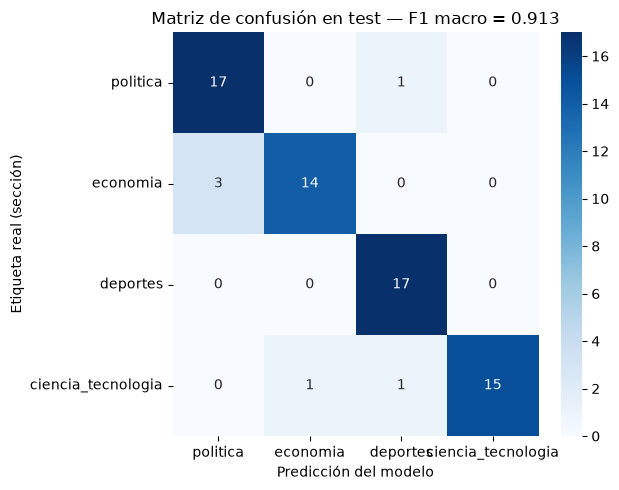

In [8]:
inicio = time.time()
pred = trainer.predict(ds_test)
latencia_ft = (time.time() - inicio) / len(test)
y_test = pred.label_ids
y_pred = pred.predictions.argmax(axis=-1)

acc_test = accuracy_score(y_test, y_pred)
f1_test = f1_score(y_test, y_pred, average="macro")
print(f"TEST ({len(test)} titulares) | accuracy = {acc_test:.3f} | F1 macro = {f1_test:.3f}")
print(classification_report(y_test, y_pred, labels=range(4), target_names=CATEGORIAS,
                            zero_division=0))

matriz = confusion_matrix(y_test, y_pred, labels=range(4))
plt.figure(figsize=(6.5, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción del modelo"); plt.ylabel("Etiqueta real (sección)")
plt.title(f"Matriz de confusión en test — F1 macro = {f1_test:.3f}")
plt.tight_layout(); plt.show()

In [9]:
errores = test.assign(prediccion=[id2label[i] for i in y_pred])
errores = errores[errores["prediccion"] != errores["etiqueta"]]
print(f"Errores en test: {len(errores)}")
display(errores[["titular", "etiqueta", "prediccion", "etiqueta_llm"]])

Errores en test: 6


,titular,etiqueta,prediccion,etiqueta_llm
295,Juan Sheput sobre los 16 feriados en Perú: “No se van a aumentar ni disminuir por ahora”,economia,politica,politica
297,"Edmundo Lizarzaburu, presidente de Petroperú: ""La refinería puede producir 95 mil barriles, pero hoy la fa...",economia,politica,economia
395,"Cayó ‘Leo’, lugarteniente de la banda ‘Los Sanguinarios de La Pampa’ y rival de El Chili",politica,deportes,politica
74,Cyber Wow 2026 día 3: Alu entra en la recta final con 48 horas de descuento por delante,ciencia_tecnologia,deportes,economia
283,Julio Velarde es ratificado por el Senado: ¿qué viene ahora para el BCR?,economia,politica,economia
71,"Huawei Mate 80 Pro: prueba real de su cámara, zoom y rendimiento en fotografía",ciencia_tecnologia,economia,ciencia_tecnologia


### Reflexión por categoría

* **Mejor desempeño: `deportes` y `ciencia_tecnologia` (F1 ≈ 0.94).** Deportes tiene *recall* perfecto:
  su vocabulario es casi exclusivo (clubes, "partido", "hora y canal", torneos, marcadores). Sus 2 errores son
  falsos positivos que **toman prestado el léxico de competencia**: *"Cayó 'Leo', lugarteniente de la banda…"*
  (apodos entre comillas y "rival", típicos de crónica deportiva) y *"Cyber Wow 2026 día 3: … recta final"*.
  Ciencia y tecnología no tiene falsos positivos (precisión 1.00); pierde 2 notas de **productos y comercio**
  publicadas en la sección *tecnología* (Cyber Wow, reseña del Huawei Mate 80 Pro), que por contenido están
  más cerca de consumo que de ciencia.
* **Peor desempeño: `economia` (F1 ≈ 0.88, *recall* 0.82) y `politica` (F1 ≈ 0.89, precisión 0.85).**
  El error dominante es **economía → política**: *"Julio Velarde es ratificado por el Senado"*,
  *"presidente de Petroperú…"*, *"Juan Sheput sobre los 16 feriados"*. Son noticias económicas narradas con
  **actores e instituciones del Estado** (Senado, empresas estatales, congresistas), así que comparten
  vocabulario con política. Es la misma frontera donde el LLM discrepó más de la sección (10 casos).
* **Ruido heredado de la supervisión débil:** en 2 de los 6 errores (Sheput y Cyber Wow) el LLM ya había
  etiquetado distinto a la sección, y el modelo aprendió esa misma lectura. Con etiquetas débiles, el techo del
  clasificador queda cerca de la calidad del etiquetador.

## 6. Comparativa y decisión

Para que la comparación sea justa, el LLM también se mide **sobre el mismo test** (sus etiquetas
contra la sección editorial).

In [10]:
acc_llm_test = accuracy_score(test["etiqueta"], test["etiqueta_llm"])
f1_llm_test = f1_score(test["etiqueta"], test["etiqueta_llm"], average="macro")
f1_llm_total = f1_score(df["etiqueta"], df["etiqueta_llm"], average="macro")

comparativa = pd.DataFrame([
    {"enfoque": "Zero-shot (BETO-XNLI)", "evaluado_sobre": "40 titulares",
     "accuracy": acc_zs, "f1_macro": f1_zs,
     "latencia": f"{latencia_zs * 1000:.0f} ms/titular ({DISPOSITIVO})",
     "costo": "sin entrenamiento; modelo de 440 MB"},
    {"enfoque": f"LLM débil ({MODELO_LLM})", "evaluado_sobre": f"test ({len(test)})",
     "accuracy": acc_llm_test, "f1_macro": f1_llm_test,
     "latencia": "~1-3 s por lote de 20 (red + API)",
     "costo": "API externa; cuota y dependencia de internet"},
    {"enfoque": "DistilBERT fine-tuned", "evaluado_sobre": f"test ({len(test)})",
     "accuracy": acc_test, "f1_macro": f1_test,
     "latencia": f"{latencia_ft * 1000:.0f} ms/titular ({DISPOSITIVO})",
     "costo": "entrenamiento de minutos en CPU; ~540 MB de pesos"},
]).round(3)
display(comparativa)
print(f"(F1 macro del LLM sobre el dataset completo: {f1_llm_total:.3f})")

metricas_app = {
    "f1_macro_test": round(float(f1_test), 3),
    "accuracy_test": round(float(acc_test), 3),
    "f1_zero_shot": round(float(f1_zs), 3),
    "f1_llm_test": round(float(f1_llm_test), 3),
    "acuerdo_llm_humano": f"{n_acuerdo}/20",
    "modelo": MODELO_BASE,
    "modelo_llm": MODELO_LLM,
    "n_noticias": int(len(df)),
}
(RUTA_MODELO / "metrics.json").write_text(json.dumps(metricas_app, ensure_ascii=False, indent=2),
                                          encoding="utf-8")
print(json.dumps(metricas_app, ensure_ascii=False, indent=2))

,enfoque,evaluado_sobre,accuracy,f1_macro,latencia,costo
0,Zero-shot (BETO-XNLI),40 titulares,0.675,0.672,216 ms/titular (CPU),sin entrenamiento; modelo de 440 MB
1,LLM débil (gemini-3.5-flash-lite),test (69),0.942,0.942,~1-3 s por lote de 20 (red + API),API externa; cuota y dependencia de internet
2,DistilBERT fine-tuned,test (69),0.913,0.913,19 ms/titular (CPU),entrenamiento de minutos en CPU; ~540 MB de pesos


(F1 macro del LLM sobre el dataset completo: 0.950)
{
  "f1_macro_test": 0.913,
  "accuracy_test": 0.913,
  "f1_zero_shot": 0.672,
  "f1_llm_test": 0.942,
  "acuerdo_llm_humano": "20/20",
  "modelo": "distilbert-base-multilingual-cased",
  "modelo_llm": "gemini-3.5-flash-lite",
  "n_noticias": 458
}


### Decisión

**Para un entorno real se elige el DistilBERT fine-tuned.**

* **Precisión:** el fine-tuned (F1 0.913) supera por mucho al zero-shot (0.672) y queda apenas por debajo del
  LLM (0.942) en el mismo test. Esa diferencia equivale a **2 titulares de 69**, dentro del margen de error de un
  test tan pequeño. Además, el fine-tuned aprendió de las etiquetas del LLM, así que es lógico que no lo supere.
* **Latencia:** ~17 ms por titular en CPU frente a 1–3 s por llamada al LLM (red + API). Para un dashboard que
  clasifica en vivo, la diferencia se nota.
* **Costo y fiabilidad:** el modelo corre local, sin API key, sin cuota y sin internet. Durante este trabajo la
  API de Gemini respondió **503 (saturada)** varias veces y hubo que cambiar de modelo: eso en producción es un
  riesgo real. El LLM además puede cambiar de versión o retirarse (Gemini 2.5 ya no estaba disponible).
* **Rol de cada enfoque:** el **LLM** queda como **etiquetador** para ampliar y reentrenar el dataset con noticias
  nuevas (más barato que anotar a mano y validado con la auditoría 20/20); el **zero-shot** solo sirve como
  respaldo si no hay modelo entrenado.